# 08 · Building a GPT: a Generalist Model from Next-Token Prediction

**GPT** = **G**enerative **P**re-trained **T**ransformer. It is the decoder half of notebook 07's transformer, trained on one deceptively simple objective:

> given the text so far, predict the next token.

Do that on enough varied text and the model has to pick up grammar, facts, arithmetic, translation and reasoning patterns, because they all help predict what comes next. The *same* network then performs a task chosen simply by how the prompt is written. That is what makes it a **generalist**.

In this notebook we build a GPT from scratch and pre-train it on a small multi-task corpus (arithmetic, string reversal, sorting, English → Spanish translation and world capitals), all written as plain text. One model, one loss, five skills.

**Contents**
1. GPT in context
2. Tokenisation: characters, words and Byte-Pair Encoding (BPE)
3. A multi-task pre-training corpus
4. The GPT architecture
5. Before training: a model that knows nothing
6. Pre-training, and watching skills emerge
7. Using the generalist: prompting for different tasks (and hallucination)
8. Sampling: greedy, temperature, top-k, top-p
9. Inside the model: attention while doing arithmetic
10. Fast generation with a KV cache
11. Fine-tuning: why pre-training matters
12. From a base model to ChatGPT, and scaling laws
13. Exercises

⏱ Runtime: about 15 minutes on a laptop CPU, almost all of it in section 6.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import math, random, time
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

random.seed(0); np.random.seed(0); torch.manual_seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))

## 1. GPT in context

| Model | Year | Parameters | Training tokens | What changed |
|---|---|---|---|---|
| GPT-1 | 2018 | 117 M | ~1 B | pre-train on books, then fine-tune per task |
| GPT-2 | 2019 | 1.5 B | ~10 B (WebText) | zero-shot tasks just from prompts |
| GPT-3 | 2020 | 175 B | ~300 B | **in-context learning**: show a few examples in the prompt |
| InstructGPT / ChatGPT | 2022 | (GPT-3.5) | + human feedback | instruction tuning + RLHF turn a base model into an assistant |
| GPT-4 and later frontier models | 2023+ | not disclosed | not disclosed | multimodal, far larger, mixture-of-experts, long context, tool use |

The architecture barely changed across this table. What grew was **scale** (parameters, data, compute) and the **post-training** that turns a text predictor into a helpful assistant. The model we build has the same structure as GPT-2, just about 2,000 times smaller.

## 2. Tokenisation

A model reads integers, not text. Three options for the mapping:

| Unit | Vocabulary | Sequence length | Problem |
|---|---|---|---|
| Characters | tiny (~100) | long | the model must learn spelling; sequences get long |
| Words | huge (100k+) | short | unknown words, no sharing between "run" / "running" |
| **Subwords (BPE)** | chosen (GPT-2: 50,257) | medium | the standard compromise |

**Byte-Pair Encoding** starts from characters and repeatedly **merges the most frequent adjacent pair** into a new token. Frequent words become one token, rare words are split into reusable pieces. Below is the whole algorithm.

In [2]:
sample_text = (
    "the model learns to predict the next token. the next token depends on the tokens before it. "
    "a token can be a word, a part of a word, or a single character. learning to predict the next "
    "word teaches the model grammar, facts and reasoning, because all of them help prediction. "
    "transformers use attention to let every token look at the tokens that came before it."
)

def bpe_train(text, n_merges):
    seq = list(text)                         # start from characters
    merges = []
    for _ in range(n_merges):
        pairs = Counter(zip(seq, seq[1:]))
        (a, b), count = pairs.most_common(1)[0]
        if count < 2:
            break
        merges.append((a, b))
        new, i = [], 0
        while i < len(seq):                  # replace every occurrence of the pair
            if i < len(seq) - 1 and seq[i] == a and seq[i + 1] == b:
                new.append(a + b); i += 2
            else:
                new.append(seq[i]); i += 1
        seq = new
    return merges, seq

def bpe_encode(text, merges):
    seq = list(text)
    for a, b in merges:                      # apply merges in the order they were learned
        new, i = [], 0
        while i < len(seq):
            if i < len(seq) - 1 and seq[i] == a and seq[i + 1] == b:
                new.append(a + b); i += 2
            else:
                new.append(seq[i]); i += 1
        seq = new
    return seq

merges, tokens = bpe_train(sample_text, 40)
print("first 15 merges:", [a + b for a, b in merges[:15]])
print(f"\n{len(sample_text)} characters -> {len(tokens)} tokens after {len(merges)} merges "
      f"({len(sample_text) / len(tokens):.1f} chars per token)\n")
print("encoding a new sentence:", bpe_encode("the next word predicts the model", merges))

first 15 merges: [' t', 'e ', ' to', ' th', 'en', 'or', ' tok', ' token', ' a', 'ar', 'ct', ' l', ' p', 're', ' the ']

360 characters -> 178 tokens after 40 merges (2.0 chars per token)

encoding a new sentence: ['t', 'h', 'e ', 'n', 'e', 'x', 't ', 'word', ' predict', 's', ' the ', 'mode', 'l']


Notice that common words like *the* and *token* became single tokens, while new words are built from pieces. Real tokenisers run BPE on **bytes** over terabytes of text.

For our tiny model we use **characters**: a vocabulary of about 40 symbols keeps the model small and lets it see exactly how arithmetic and reversal work digit by digit. Everything else in this notebook is identical for a BPE vocabulary.

## 3. A multi-task pre-training corpus

Real GPTs are pre-trained on web pages, books, code and papers, which implicitly contain countless "tasks". We imitate that with five task types, mixed into one stream of plain text, one example per line:

| Task | Example line | What it requires |
|---|---|---|
| `add` | `add 23+58=81` | an algorithm (carrying digits) |
| `rev` | `rev kqzpa=apzqk` | an algorithm (copying in reverse) |
| `sort` | `sort 5 2 9 2=2 2 5 9` | an algorithm (ordering) |
| `es` | `es she wants the red car=ella quiere el coche rojo` | language: vocabulary, conjugation, agreement, word order |
| `capital` | `capital peru=lima` | memorised **facts** |

To test real **generalisation** we hold out 500 addition problems and 120 sentences the model never sees during training, and reversal uses fresh random strings every time. Capitals can only be memorised, so for them we test recall of training facts.

In [3]:
COUNTRIES = {"france": "paris", "spain": "madrid", "italy": "rome", "germany": "berlin", "portugal": "lisbon",
             "japan": "tokyo", "egypt": "cairo", "peru": "lima", "chile": "santiago", "kenya": "nairobi",
             "canada": "ottawa", "norway": "oslo", "greece": "athens", "poland": "warsaw", "cuba": "havana",
             "india": "new delhi", "china": "beijing", "russia": "moscow", "mexico": "mexico city", "ireland": "dublin",
             "austria": "vienna", "sweden": "stockholm", "finland": "helsinki", "turkey": "ankara", "brazil": "brasilia",
             "argentina": "buenos aires", "colombia": "bogota", "costa rica": "san jose", "morocco": "rabat", "australia": "canberra"}

SUBJ = [("i", "yo", 0), ("you", "tú", 1), ("he", "él", 2), ("she", "ella", 2), ("we", "nosotros", 3), ("they", "ellos", 4)]
VERB = {"eat": ("eats", ["como", "comes", "come", "comemos", "comen"]),
        "see": ("sees", ["veo", "ves", "ve", "vemos", "ven"]),
        "want": ("wants", ["quiero", "quieres", "quiere", "queremos", "quieren"]),
        "buy": ("buys", ["compro", "compras", "compra", "compramos", "compran"]),
        "have": ("has", ["tengo", "tienes", "tiene", "tenemos", "tienen"])}
NOUN = [("apple", "manzana", "f"), ("book", "libro", "m"), ("car", "coche", "m"), ("house", "casa", "f"),
        ("dog", "perro", "m"), ("table", "mesa", "f"), ("cat", "gato", "m"), ("shirt", "camisa", "f")]
ADJ = [("red", "rojo", "roja"), ("new", "nuevo", "nueva"), ("old", "viejo", "vieja"), ("white", "blanco", "blanca"), (None, None, None)]

def translation_pairs():
    out = []
    for en_s, es_s, p in SUBJ:
        for v, (v3, conj) in VERB.items():
            for en_n, es_n, g in NOUN:
                for en_a, am, af in ADJ:
                    en = f"{en_s} {v3 if en_s in ('he', 'she') else v} the {en_a + ' ' if en_a else ''}{en_n}"
                    es = f"{es_s} {conj[p]} {'el' if g == 'm' else 'la'} {es_n}" + (f" {am if g == 'm' else af}" if en_a else "")
                    out.append((en, es))
    return out

ALL_TR = translation_pairs()
random.shuffle(ALL_TR)
TR_TEST, TR_TRAIN = ALL_TR[:120], ALL_TR[120:]
ADD_ALL = [(a, b) for a in range(100) for b in range(100)]
random.shuffle(ADD_ALL)
ADD_TEST, ADD_TRAIN = ADD_ALL[:500], ADD_ALL[500:]

def rand_word():
    return "".join(random.choice("abcdefghijklmnopqrstuvwxyz") for _ in range(random.randint(3, 6)))

def example(task, split="train"):
    # returns (prompt, answer); a training line is prompt + answer
    if task == "add":
        a, b = random.choice(ADD_TRAIN if split == "train" else ADD_TEST)
        return f"add {a}+{b}=", f"{a + b}"
    if task == "rev":
        w = rand_word()
        return f"rev {w}=", w[::-1]
    if task == "sort":
        ds = [random.randint(0, 9) for _ in range(random.randint(3, 6))]
        return f"sort {' '.join(map(str, ds))}=", " ".join(map(str, sorted(ds)))
    if task == "es":
        en, es = random.choice(TR_TRAIN if split == "train" else TR_TEST)
        return f"es {en}=", es
    if task == "capital":
        c = random.choice(list(COUNTRIES))
        return f"capital {c}=", COUNTRIES[c]

TASKS = ["add", "rev", "sort", "es", "capital"]
WEIGHTS = [5, 1, 2, 1, 1]          # arithmetic is the hardest skill, so it gets more data
corpus = "\n".join("".join(example(random.choices(TASKS, WEIGHTS)[0])) for _ in range(60000)) + "\n"

print(f"corpus: {len(corpus):,} characters, {corpus.count(chr(10)):,} lines\n")
print(corpus[:400])

corpus: 1,194,459 characters, 60,000 lines

es you have the white table=tú tienes la mesa blanca
add 10+13=23
rev nmnhrz=zrhnmn
add 43+55=98
capital canada=ottawa
add 48+20=68
add 6+63=69
add 45+78=123
add 2+66=68
add 50+33=83
rev jkpct=tcpkj
rev twd=dwt
add 79+2=81
add 18+75=93
add 49+40=89
add 41+51=92
sort 3 4 8=3 4 8
add 90+5=95
rev hghj=jhgh
sort 3 7 1=1 3 7
add 15+66=81
sort 6 5 7 2 9 9=2 5 6 7 9 9
add 34+25=59
capital australia=canbe


In [4]:
chars = sorted(set(corpus) | set("".join(e for pair in ALL_TR for e in pair)))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)
data = torch.tensor(encode(corpus), dtype=torch.long)

print(f"vocabulary ({len(chars)} tokens): {''.join(chars)!r}")
print("encode('add 2+2=4') ->", encode("add 2+2=4"))

vocabulary (42 tokens): '\n +0123456789=abcdefghijklmnopqrstuvwxyzéú'
encode('add 2+2=4') -> [14, 17, 17, 1, 5, 2, 5, 13, 7]


**Training examples are just windows of text.** We cut random chunks of `BLOCK = 64` characters from the corpus. The input is the chunk, the target is the same chunk shifted by one character. So every position in every chunk is a training example: *"given `add 23+5`, predict `8`"*. One chunk of 64 characters gives 64 predictions at once, thanks to the causal mask.

In [5]:
BLOCK = 64

def get_batch(B, source=None):
    source = data if source is None else source
    ix = torch.randint(len(source) - BLOCK - 1, (B,))
    x = torch.stack([source[i:i + BLOCK] for i in ix])
    y = torch.stack([source[i + 1:i + BLOCK + 1] for i in ix])
    return x, y

x, y = get_batch(1)
for t in range(12):
    print(f"context {decode(x[0, :t + 1].tolist())!r:22s} -> target {decode([y[0, t].item()])!r}")

context 't'                    -> target ' '
context 't '                   -> target '4'
context 't 4'                  -> target ' '
context 't 4 '                 -> target '3'
context 't 4 3'                -> target ' '
context 't 4 3 '               -> target '6'
context 't 4 3 6'              -> target ' '
context 't 4 3 6 '             -> target '9'
context 't 4 3 6 9'            -> target ' '
context 't 4 3 6 9 '           -> target '7'
context 't 4 3 6 9 7'          -> target '='
context 't 4 3 6 9 7='         -> target '3'


## 4. The GPT architecture

Exactly the decoder block from notebook 07, minus cross-attention (there is no encoder):

```
token ids ─► token embedding ─┐
positions ─► position embedding (learned) ─(+)─► [Block] × N ─► LayerNorm ─► Linear (tied to the embedding) ─► logits

Block:  x = x + CausalSelfAttention(LayerNorm(x))      # read earlier tokens
        x = x + MLP(LayerNorm(x))                      # think about them
```

Details that match GPT-2:
* **Learned** position embeddings instead of sinusoids.
* **Weight tying:** the output layer reuses the input embedding matrix (a token's "meaning" vector is used both to read and to write it), saving parameters.
* Small normal initialisation (std 0.02).
* `scaled_dot_product_attention` is PyTorch's fused (FlashAttention-style) kernel for $\text{softmax}(QK^\top/\sqrt{d})V$ with a causal mask. We also keep a slow explicit path so we can look at the attention weights.
* `past` lets the model reuse keys and values from earlier steps: the **KV cache** (section 10).

In [6]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d, n_head, block_size):
        super().__init__()
        self.h = n_head
        self.qkv = nn.Linear(d, 3 * d)            # Q, K and V projections in one matrix
        self.proj = nn.Linear(d, d)               # W_O
        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size, dtype=torch.bool)))
        self.last_attn = None

    def forward(self, x, past=None, keep_attn=False):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)
        q, k, v = (t.view(B, T, self.h, D // self.h).transpose(1, 2) for t in (q, k, v))   # (B, heads, T, dh)
        if past is not None:                       # KV cache: prepend keys/values of earlier tokens
            k, v = torch.cat([past[0], k], dim=2), torch.cat([past[1], v], dim=2)
        present = (k, v)
        if keep_attn:                              # explicit version, keeps the weights for plotting
            Tk = k.shape[2]
            att = (q @ k.transpose(-2, -1)) / math.sqrt(D // self.h)
            att = att.masked_fill(~self.mask[Tk - T:Tk, :Tk], float("-inf")).softmax(-1)
            self.last_attn = att.detach()
            y = att @ v
        else:                                      # fused kernel, same maths, faster
            y = F.scaled_dot_product_attention(q, k, v, is_causal=(past is None and T > 1))
        return self.proj(y.transpose(1, 2).reshape(B, T, D)), present

class Block(nn.Module):
    def __init__(self, d, n_head, block_size):
        super().__init__()
        self.ln1, self.attn = nn.LayerNorm(d), CausalSelfAttention(d, n_head, block_size)
        self.ln2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x, past=None, keep_attn=False):
        a, present = self.attn(self.ln1(x), past, keep_attn)
        x = x + a
        return x + self.mlp(self.ln2(x)), present

class GPT(nn.Module):
    def __init__(self, vocab, block_size=64, d=128, n_layer=4, n_head=4):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab, d)
        self.pos_emb = nn.Embedding(block_size, d)
        self.blocks = nn.ModuleList(Block(d, n_head, block_size) for _ in range(n_layer))
        self.ln_f = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab, bias=False)
        self.head.weight = self.tok_emb.weight                 # weight tying
        self.apply(self._init)

    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None, past=None, keep_attn=False):
        B, T = idx.shape
        start = 0 if past is None else past[0][0].shape[2]
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(start, start + T))
        presents = []
        for i, blk in enumerate(self.blocks):
            x, pr = blk(x, None if past is None else past[i], keep_attn)
            presents.append(pr)
        logits = self.head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss, presents

torch.manual_seed(0)
model = GPT(len(chars), BLOCK, d=128, n_layer=4, n_head=4)
n_params = sum(p.numel() for p in model.parameters())
print(f"GPT with {n_params:,} parameters (GPT-2 small has 124 million, GPT-3 has 175 billion)")

GPT with 806,912 parameters (GPT-2 small has 124 million, GPT-3 has 175 billion)


## 5. Before training: a model that knows nothing

With random weights, every next character is roughly equally likely, so the loss should be about $-\ln(1/V) = \ln V$. Checking this is a standard sanity test before a long training run.

In [7]:
@torch.no_grad()
def complete(model, prompt, max_new=40):
    # greedy decoding until a newline: the answer to a task prompt
    idx = torch.tensor([encode("\n" + prompt)])
    out = []
    for _ in range(max_new):
        logits, _, _ = model(idx[:, -BLOCK:])
        nxt = logits[0, -1].argmax().item()
        if itos[nxt] == "\n":
            break
        out.append(nxt)
        idx = torch.cat([idx, torch.tensor([[nxt]])], dim=1)
    return decode(out)

xb, yb = get_batch(64)
with torch.no_grad():
    _, loss0, _ = model(xb, yb)
print(f"initial loss {loss0.item():.3f}   vs   ln(vocab) = {math.log(len(chars)):.3f}")
print("untrained answer to 'add 2+2=':", repr(complete(model, "add 2+2=", 20)))

initial loss 3.783   vs   ln(vocab) = 3.738
untrained answer to 'add 2+2=': '=n55555555555rrrrrrr'


## 6. Pre-training, and watching skills emerge

The loop is the same as every notebook before: forward, cross-entropy loss, backward, AdamW step. Additions used by real LLM training:
* **AdamW** with weight decay and $\beta_2 = 0.95$ (GPT-3's settings),
* **learning-rate warm-up then cosine decay** (`OneCycleLR`),
* **gradient clipping** at norm 1.0.

Every 400 steps we pause and measure accuracy on each task's **held-out** prompts. This shows something you also see in large models: **different skills appear at different times**. The total loss falls smoothly, but individual abilities can switch on fairly suddenly.

In [8]:
def evaluate(model, n=60, seed=1234):
    state = random.getstate(); random.seed(seed)       # same test prompts every time
    model.eval()
    res = {}
    for t in TASKS:
        ok = 0
        for _ in range(n):
            p, a = example(t, "test")
            ok += complete(model, p) == a
        res[t] = ok / n
    model.train(); random.setstate(state)
    return res

STEPS, BATCH, EVAL_EVERY = 2500, 32, 500
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=0.1, betas=(0.9, 0.95))
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=STEPS, pct_start=0.05)

losses, skill_curve = [], {0: evaluate(model)}
t0 = time.time()
for step in range(1, STEPS + 1):
    xb, yb = get_batch(BATCH)
    _, loss, _ = model(xb, yb)
    opt.zero_grad(); loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step(); sched.step()
    losses.append(loss.item())
    if step % EVAL_EVERY == 0:
        skill_curve[step] = evaluate(model)
        accs = "  ".join(f"{t} {a:.0%}" for t, a in skill_curve[step].items())
        print(f"step {step:5d}  loss {np.mean(losses[-100:]):.3f}  |  {accs}  ({time.time() - t0:.0f}s)", flush=True)

step   500  loss 0.993  |  add 0%  rev 0%  sort 0%  es 3%  capital 78%  (146s)


step  1000  loss 0.828  |  add 0%  rev 3%  sort 20%  es 92%  capital 100%  (291s)


step  1500  loss 0.710  |  add 60%  rev 43%  sort 78%  es 100%  capital 100%  (439s)


step  2000  loss 0.654  |  add 92%  rev 93%  sort 98%  es 100%  capital 100%  (584s)


step  2500  loss 0.638  |  add 98%  rev 98%  sort 100%  es 100%  capital 100%  (731s)


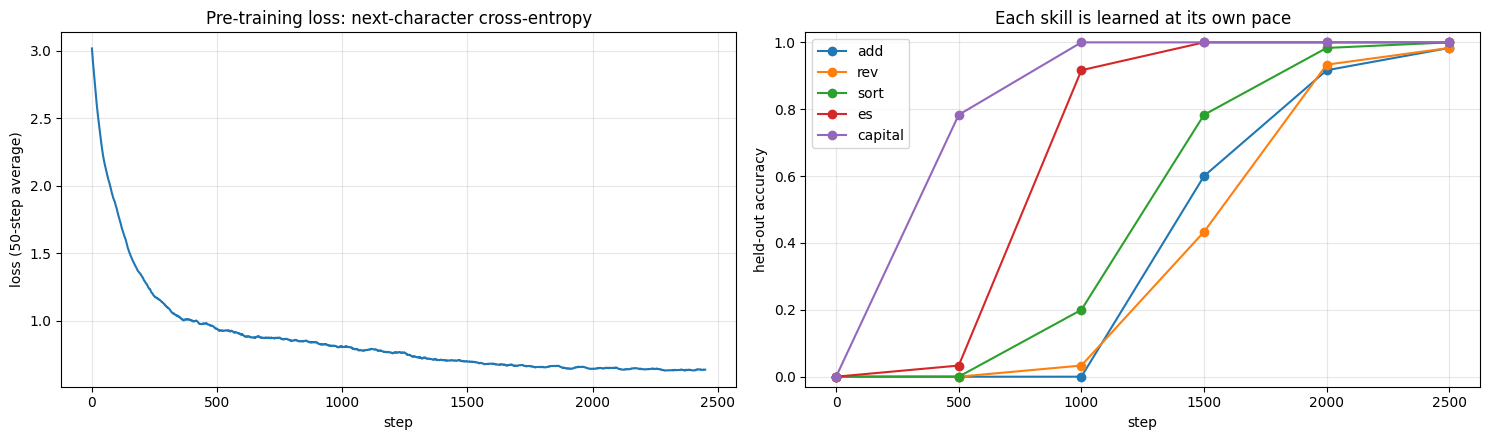

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
smooth = np.convolve(losses, np.ones(50) / 50, mode="valid")
axes[0].plot(smooth); axes[0].set_xlabel("step"); axes[0].set_ylabel("loss (50-step average)")
axes[0].set_title("Pre-training loss: next-character cross-entropy"); axes[0].grid(alpha=0.3)
steps_eval = list(skill_curve)
for t in TASKS:
    axes[1].plot(steps_eval, [skill_curve[s][t] for s in steps_eval], marker="o", label=t)
axes[1].set_xlabel("step"); axes[1].set_ylabel("held-out accuracy"); axes[1].set_ylim(-0.03, 1.03)
axes[1].set_title("Each skill is learned at its own pace"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Using the generalist

The model has no task-specific heads or code paths. The **prompt prefix alone** decides what it does. All the prompts below are **held-out**: those additions and sentences never appeared in training, and the reversal strings are new random letters.

In [10]:
model.eval()
random.seed(42)
for t in TASKS:
    print(f"--- {t} ---")
    for _ in range(3):
        p, a = example(t, "test")
        out = complete(model, p)
        print(f"  {p}{out:28s} {'✓' if out == a else '✗ expected ' + a}")

--- add ---
  add 71+42=113                          ✓
  add 39+14=53                           ✓
  add 4+41=45                           ✓
--- rev ---
  rev hhexd=dxehh                        ✓
  rev snb=bns                          ✓
  rev cgh=hgc                          ✓
--- sort ---
  sort 8 3 8=3 8 8                        ✓
  sort 3 7 9 4 0 2=0 2 3 4 7 9                  ✓
  sort 5 4 2 3 5 1=1 2 3 4 5 5                  ✓
--- es ---


  es she has the apple=ella tiene la manzana        ✓
  es we buy the new table=nosotros compramos la mesa nueva ✓


  es we want the red car=nosotros queremos el coche rojo ✓
--- capital ---
  capital norway=oslo                         ✓
  capital costa rica=san jose                     ✓
  capital norway=oslo                         ✓


### Hallucination: confident answers to questions it cannot know

The model learned the *format* of a capital-city answer, not a way to say "I don't know". Ask about countries it never saw (or don't exist) and it still produces a plausible-looking city, usually a blend of ones it memorised. Large language models hallucinate for the same reason: they are trained to produce likely text, and plausible is not the same as true. Post-training (section 12) and retrieval of real sources reduce this, but do not remove it completely.

In [11]:
for country in ["france", "peru", "japan", "atlantis", "narnia", "germanyland", "nepal", "spainia"]:
    print(f"capital {country:12s} -> {complete(model, f'capital {country}='):14s}"
          f"{'(memorised)' if country in COUNTRIES else '(never seen: hallucinated)'}")

capital france       -> paris         (memorised)
capital peru         -> lima          (memorised)
capital japan        -> tokyo         (memorised)
capital atlantis     -> moscow        (never seen: hallucinated)


capital narnia       -> buenos aires  (never seen: hallucinated)
capital germanyland  -> helsinki      (never seen: hallucinated)
capital nepal        -> stockholm     (never seen: hallucinated)
capital spainia      -> madrid        (never seen: hallucinated)


### Generalisation beyond the training distribution

The test prompts above were unseen but *in distribution*. What happens with inputs that look different from anything in training?

In [12]:
probes = [("add 123+4=", "127", "3-digit number (training used 0..99)"),
          ("rev abcdefghij=", "jihgfedcba", "10-letter word (training used 3..6)"),
          ("sort 9 8 7 6 5 4 3 2 1=", "1 2 3 4 5 6 7 8 9", "9 digits (training used 3..6)"),
          ("es the cat eats the red apple=", "?", "noun as subject (training subjects were pronouns)")]
for p, a, why in probes:
    out = complete(model, p)
    print(f"{p:32s} -> {out:22s} expected {a:20s} [{why}]")

add 123+4=                       -> 36                     expected 127                  [3-digit number (training used 0..99)]
rev abcdefghij=                  -> hghcdcb                expected jihgfedcba           [10-letter word (training used 3..6)]
sort 9 8 7 6 5 4 3 2 1=          -> 1 2 3 4 6 7 9          expected 1 2 3 4 5 6 7 8 9    [9 digits (training used 3..6)]


es the cat eats the red apple=   -> él come la manzana roja expected ?                    [noun as subject (training subjects were pronouns)]


Small models extrapolate poorly: they learn the patterns their data covers. A large part of why frontier LLMs seem general is that their training data covers an enormous range of patterns. Robust out-of-distribution generalisation is still an open research problem.

## 8. Sampling strategies

The model outputs a probability distribution over the next token. How we pick from it changes the behaviour:

| Strategy | Rule | Effect |
|---|---|---|
| Greedy | take the argmax | deterministic, best for tasks with one right answer |
| Temperature $T$ | sample from softmax(logits / $T$) | $T<1$ sharper and safer, $T>1$ more random and creative |
| Top-k | keep only the $k$ most likely tokens | cuts off the long tail of nonsense |
| Top-p (nucleus) | keep the smallest set with total probability ≥ $p$ | adapts the cut-off to how confident the model is |

First, look at the distribution itself for two prompts: one where the answer is certain, one where many continuations are valid.

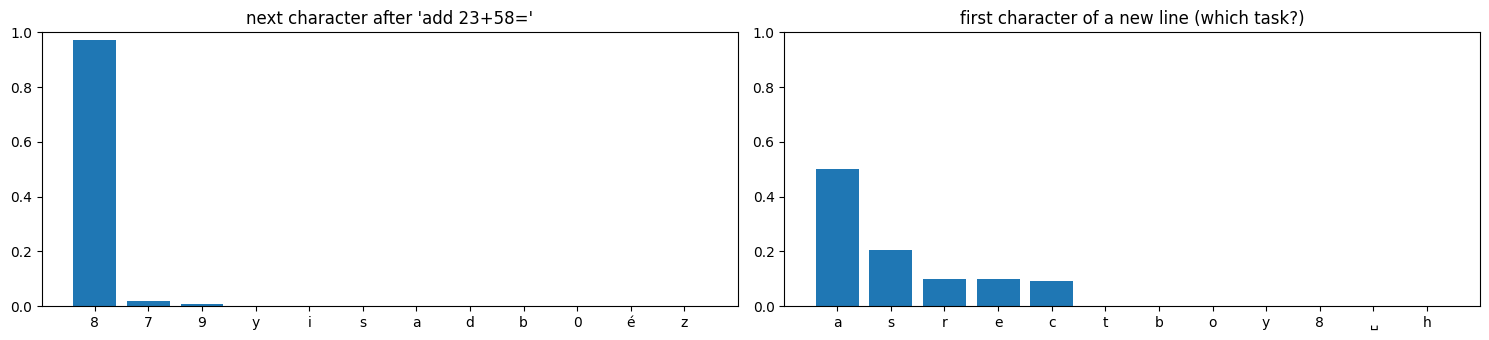

In [13]:
@torch.no_grad()
def next_char_probs(prompt):
    logits, _, _ = model(torch.tensor([encode("\n" + prompt)]))
    return logits[0, -1].softmax(-1)

fig, axes = plt.subplots(1, 2, figsize=(15, 3.5))
for ax, prompt in zip(axes, ["add 23+58=", "\n"]):
    p = next_char_probs(prompt if prompt != "\n" else "")
    top = p.topk(12)
    labels = [repr(itos[i])[1:-1] if itos[i] != " " else "␣" for i in top.indices.tolist()]
    ax.bar(labels, top.values.numpy(), color="tab:blue")
    ax.set_title(f"next character after {prompt!r}" if prompt != "\n" else "first character of a new line (which task?)")
    ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

In [14]:
@torch.no_grad()
def generate(model, prompt="\n", max_new=200, temperature=1.0, top_k=None, top_p=None, seed=0):
    g = torch.Generator().manual_seed(seed)
    idx = torch.tensor([encode(prompt)])
    for _ in range(max_new):
        logits, _, _ = model(idx[:, -BLOCK:])
        logits = logits[0, -1]
        if temperature == 0:
            nxt = logits.argmax().view(1)
        else:
            logits = logits / temperature
            if top_k is not None:
                kth = logits.topk(top_k).values[-1]
                logits = logits.masked_fill(logits < kth, float("-inf"))
            probs = logits.softmax(-1)
            if top_p is not None:
                sorted_p, order = probs.sort(descending=True)
                keep = sorted_p.cumsum(0) - sorted_p < top_p        # smallest set reaching top_p
                probs = torch.zeros_like(probs).scatter(0, order[keep], sorted_p[keep])
                probs = probs / probs.sum()
            nxt = torch.multinomial(probs, 1, generator=g)
        idx = torch.cat([idx, nxt.view(1, 1)], dim=1)
    return decode(idx[0].tolist())

for label, kw in [("greedy (T=0)", dict(temperature=0)),
                  ("T=0.5", dict(temperature=0.5)),
                  ("T=1.0, top-p 0.9", dict(temperature=1.0, top_p=0.9)),
                  ("T=2.0 (too hot)", dict(temperature=2.0))]:
    text = generate(model, "\n", max_new=150, **kw)
    print(f"===== {label} =====\n{text.strip()}\n")

===== greedy (T=0) =====
add 99+99=198
add 15+60=75
add 77+84=161
add 18+88=106
add 74+87=161
add 18+84=102
add 74+87=161
add 18+84=102
add 74+87=161
add 18+84=102
add 74+87=1



===== T=0.5 =====
add 87+74=161
add 29+27=56
add 60+6=66
add 55+52=107
add 68+88=156
add 6+59=65
add 41+39=70
rev xaz=zax
capital china=beijing
add 65+31=96
add 49+35=8



===== T=1.0, top-p 0.9 =====
sort 7 7 2 1 6 7=1 2 6 7 7 7
add 61+90=151
rev izktws=swtkzi
add 95+22=117
add 85+74=169
add 58+74=132
add 73+27=100
add 79+12=91
add 16+66=82
sort 7



===== T=2.0 (too hot) =====
scra
add 2chilzdn=29
add 38+17=64
re0 2 7=0 bjbiy
sos they wants thy the ixple=e5 denfo
es i see the shirtue3 2 2 2=u3 veo9
sort 9 5=5ú
capital brazil



With no prompt, the model "dreams up" its own training data: it picks a task and writes an example. Greedy decoding gets stuck repeating the single most likely line; moderate temperature gives varied, mostly valid lines; high temperature breaks the format. This is the same knob you set in any LLM API.

## 9. Inside the model: attention while doing arithmetic

To write the answer to `add 47+38=`, the model must find the right digits of both numbers. We plot every head's attention from the last few positions (where the answer digits are produced) back over the prompt.

add 47+38=85


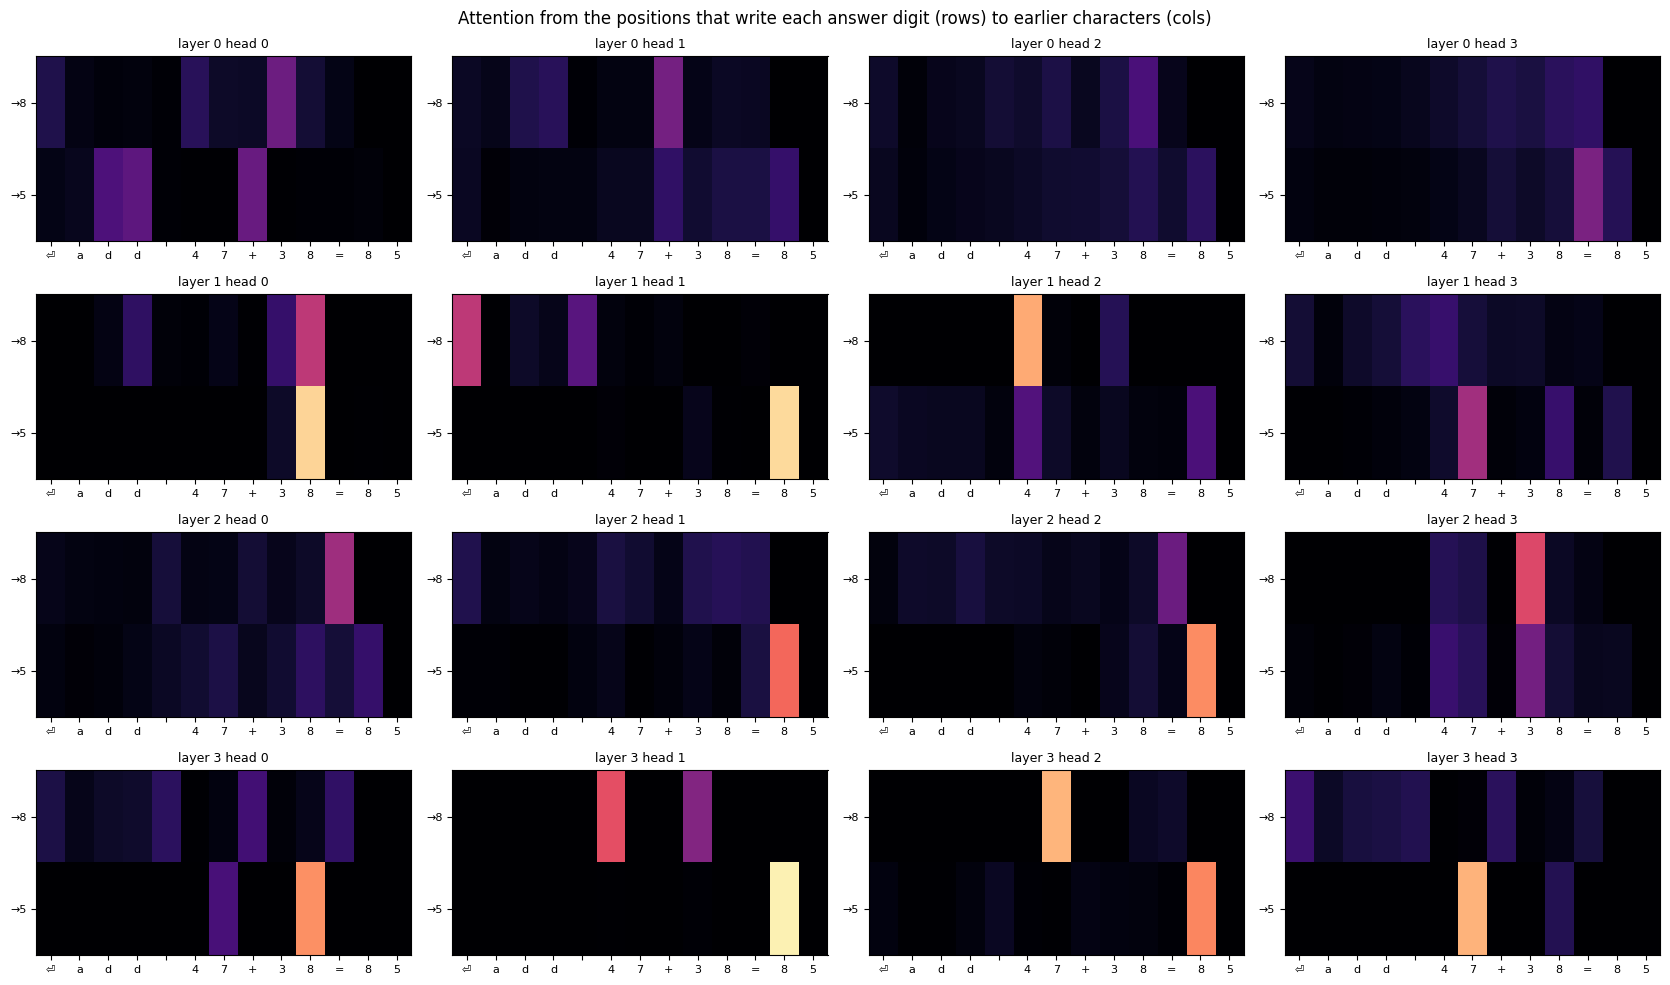

In [15]:
prompt = "add 47+38="
answer = complete(model, prompt)
full = "\n" + prompt + answer
idx = torch.tensor([encode(full)])
with torch.no_grad():
    model(idx, keep_attn=True)
labels = [c if c != "\n" else "⏎" for c in full]
q_rows = list(range(len(full) - len(answer) - 1, len(full) - 1))   # positions that predict each answer digit
print(f"{prompt}{answer}")

L, H = len(model.blocks), model.blocks[0].attn.h
fig, axes = plt.subplots(L, H, figsize=(4.2 * H, 2.5 * L))
for l in range(L):
    for h in range(H):
        A = model.blocks[l].attn.last_attn[0, h][q_rows].numpy()
        ax = axes[l, h]
        ax.imshow(A, cmap="magma", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8)
        ax.set_yticks(range(len(q_rows))); ax.set_yticklabels([f"→{answer[i]}" for i in range(len(answer))], fontsize=8)
        ax.set_title(f"layer {l} head {h}", fontsize=9)
fig.suptitle("Attention from the positions that write each answer digit (rows) to earlier characters (cols)")
plt.tight_layout(); plt.show()

Look for heads that put their weight on the digits of the two operands in the same column (tens with tens, units with units): these heads gather the inputs that an adder needs, while the MLPs perform the actual digit arithmetic. Other heads attend to the `=` or `+` signs, which mark *where* in the problem the model is. Interpretability research on large models finds similar "induction" and "copying" heads.

## 10. Fast generation with a KV cache

Generating token $t$ requires attention over all $t-1$ earlier tokens. Without caching, each step recomputes keys and values for the whole prefix: $O(n^2)$ work for $n$ tokens. Since earlier keys and values never change (causal mask!), we can **cache** them and only compute the new token's $q, k, v$ each step. Every production LLM server does this; the cache's memory is a big reason for innovations like grouped-query attention.

In [16]:
@torch.no_grad()
def generate_greedy_nocache(model, prompt, n):
    idx = torch.tensor([encode(prompt)])
    for _ in range(n):
        logits, _, _ = model(idx)                       # full recompute every step
        idx = torch.cat([idx, logits[:, -1].argmax(-1, keepdim=True)], dim=1)
    return decode(idx[0].tolist())

@torch.no_grad()
def generate_greedy_cache(model, prompt, n):
    idx = torch.tensor([encode(prompt)])
    logits, _, past = model(idx)                        # process the prompt once
    out = idx
    for _ in range(n):
        nxt = logits[:, -1].argmax(-1, keepdim=True)
        out = torch.cat([out, nxt], dim=1)
        logits, _, past = model(nxt, past=past)         # only the new token goes through the model
    return decode(out[0].tolist())

prompt, n_new = "\nadd 12+30=42\nrev hello=olleh\n", BLOCK - 32
t0 = time.time(); a = generate_greedy_nocache(model, prompt, n_new); t_no = time.time() - t0
t0 = time.time(); b = generate_greedy_cache(model, prompt, n_new); t_kv = time.time() - t0
print("identical output:", a == b)
print(f"without cache {t_no * 1000:.0f} ms, with KV cache {t_kv * 1000:.0f} ms ({t_no / t_kv:.1f}x faster)")
with torch.no_grad():
    _, _, past = model(torch.tensor([encode(prompt)]))
print(f"cache: {len(past)} layers x (keys, values), each of shape {tuple(past[0][0].shape)} = (batch, heads, tokens so far, head_dim)")

identical output: True
without cache 139 ms, with KV cache 95 ms (1.5x faster)
cache: 4 layers x (keys, values), each of shape (1, 4, 30, 32) = (batch, heads, tokens so far, head_dim)


The speed-up grows with sequence length; for thousands of tokens it is enormous.

## 11. Fine-tuning: why pre-training matters

GPT-1's recipe, still used today: **pre-train** once on lots of general data, then **fine-tune** briefly on a small task-specific dataset.

New task the model has never seen: translate **Spanish → English** (`en ella quiere el coche rojo=she wants the red car`). We give two identical models the same 200 fine-tuning steps:
* one starting from our pre-trained weights (it already knows both vocabularies and how they correspond),
* one starting from random weights.

fine-tuned both in 122s
held-out ES→EN accuracy:  from pre-trained 100%   from scratch 0%


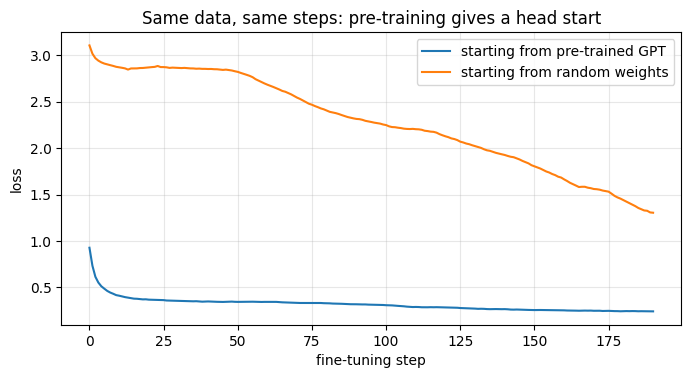

  en él come la casa=he eats the house        expected: he eats the house
  en él ve el perro nuevo=he sees the new dog      expected: he sees the new dog
  en él compra el libro viejo=he buys the old book     expected: he buys the old book


  en ella tiene la casa=she has the house        expected: she has the house


In [17]:
def new_task_example(split):
    en, es = random.choice(TR_TRAIN if split == "train" else TR_TEST)
    return f"en {es}=", en

random.seed(7)
ft_corpus = "\n".join("".join(new_task_example("train")) for _ in range(5000)) + "\n"
ft_data = torch.tensor(encode(ft_corpus), dtype=torch.long)
pretrained_state = {k: v.clone() for k, v in model.state_dict().items()}

def finetune(start_from_pretrained, steps=200):
    torch.manual_seed(0)
    m = GPT(len(chars), BLOCK, d=128, n_layer=4, n_head=4)
    if start_from_pretrained:
        m.load_state_dict(pretrained_state)
    o = torch.optim.AdamW(m.parameters(), lr=5e-4 if start_from_pretrained else 2e-3)
    curve = []
    for s in range(steps):
        xb, yb = get_batch(32, ft_data)
        _, loss, _ = m(xb, yb)
        o.zero_grad(); loss.backward(); o.step()
        curve.append(loss.item())
    m.eval()
    random.seed(99)
    acc = np.mean([complete(m, p) == a for p, a in (new_task_example("test") for _ in range(100))])
    return m, curve, acc

t0 = time.time()
ft_model, curve_pre, acc_pre = finetune(True)
_, curve_scratch, acc_scratch = finetune(False)
print(f"fine-tuned both in {time.time() - t0:.0f}s")
print(f"held-out ES→EN accuracy:  from pre-trained {acc_pre:.0%}   from scratch {acc_scratch:.0%}")

plt.figure(figsize=(8, 3.8))
plt.plot(np.convolve(curve_pre, np.ones(10) / 10, "valid"), label="starting from pre-trained GPT")
plt.plot(np.convolve(curve_scratch, np.ones(10) / 10, "valid"), label="starting from random weights")
plt.xlabel("fine-tuning step"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Same data, same steps: pre-training gives a head start"); plt.show()

random.seed(5)
for _ in range(4):
    p, a = new_task_example("test")
    print(f"  {p}{complete(ft_model, p):24s} expected: {a}")

### Catastrophic forgetting

Fine-tuning only on the new task can damage old skills, because nothing in the loss protects them. Real fine-tuning mixes in some general data or uses parameter-efficient methods like **LoRA** that freeze the original weights and train small add-on matrices.

In [18]:
after = evaluate(ft_model)
print(f"{'task':8s} {'before fine-tune':>17s} {'after':>8s}")
for t in TASKS:
    print(f"{t:8s} {skill_curve[STEPS][t]:17.0%} {after[t]:8.0%}")

task      before fine-tune    after
add                    98%      12%
rev                    98%       0%
sort                  100%      17%
es                    100%       0%
capital               100%       0%


## 12. From a base model to ChatGPT, and scaling laws

What we trained is a **base model**: it continues text in the style of its training data. Turning a base model into an assistant takes further stages:

```mermaid
flowchart LR
    A[Pre-training<br/>next-token prediction<br/>trillions of tokens] --> B[Supervised fine-tuning SFT<br/>human-written prompt → ideal answer]
    B --> C[Preference tuning<br/>RLHF with a reward model, or DPO<br/>humans rank answers]
    C --> D[Assistant<br/>+ tools, retrieval, safety systems]
```

| Stage | Data | What it teaches |
|---|---|---|
| Pre-training | web, books, code (most of the compute) | knowledge, language, skills |
| Supervised fine-tuning (SFT) | tens of thousands of curated conversations | the *format* of being an assistant: answer the question, follow instructions |
| RLHF / DPO | human (or AI) preferences between answers | be helpful, honest and harmless; refuse when appropriate; say "I don't know" |
| Tool use and retrieval | demonstrations of calling tools | look facts up instead of hallucinating (section 7), run code, browse |

Notice that our model already does a tiny version of SFT: the `task input=answer` format is an instruction format. The prompt prefix *is* the instruction.

### In-context learning

Large GPTs can learn a new task from a few examples placed **in the prompt**, with no weight updates at all (GPT-3's headline finding). Our model is far too small for that: it can only do tasks whose format it saw during training. In-context learning is one of the abilities that appears with scale.

### Scaling laws

Kaplan et al. (2020) and Hoffmann et al. (2022, "Chinchilla") found that loss falls as a smooth **power law** in parameters $N$, data $D$ and compute $C$. Two rules of thumb:
* Training compute ≈ $6ND$ floating-point operations.
* Compute-optimal training uses about **20 tokens per parameter**.

In [19]:
tokens_seen = STEPS * BATCH * BLOCK
ours = 6 * n_params * tokens_seen
rows = [("this notebook", n_params, tokens_seen),
        ("GPT-2 XL", 1.5e9, 1e10),
        ("GPT-3", 175e9, 300e9),
        ("Chinchilla", 70e9, 1.4e12)]
print(f"{'model':14s} {'params':>10s} {'tokens':>10s} {'tokens/param':>13s} {'train FLOPs (6ND)':>18s} {'× ours':>10s}")
for name, N, D in rows:
    print(f"{name:14s} {N:10.2e} {D:10.2e} {D / N:13.1f} {6 * N * D:18.2e} {6 * N * D / ours:10.1e}")

model              params     tokens  tokens/param  train FLOPs (6ND)     × ours
this notebook    8.07e+05   5.12e+06           6.3           2.48e+13    1.0e+00
GPT-2 XL         1.50e+09   1.00e+10           6.7           9.00e+19    3.6e+06
GPT-3            1.75e+11   3.00e+11           1.7           3.15e+23    1.3e+10
Chinchilla       7.00e+10   1.40e+12          20.0           5.88e+23    2.4e+10


GPT-3's training used roughly **ten billion times** the compute of the run you just did, on essentially the same architecture and the same objective.

## Key takeaways

* A GPT is a stack of **causal** transformer blocks (attention + MLP) trained to **predict the next token**.
* Text becomes integers via a tokeniser; BPE balances vocabulary size against sequence length.
* Next-token prediction on varied text forces the model to learn many skills; the **prompt** selects which one to use. That is why one model can be a generalist.
* Skills emerge at different times during training; loss is smooth, abilities can be abrupt.
* The model learns the *form* of answers, so it can **hallucinate**; it also extrapolates poorly outside its training distribution.
* Sampling (temperature, top-k, top-p) trades reliability against diversity; the **KV cache** makes generation fast.
* **Pre-training then fine-tuning** transfers knowledge; naive fine-tuning causes **forgetting**.
* Assistants such as ChatGPT add SFT and preference tuning on top of a base model, and the remaining gap is mostly **scale**.

## Exercises

1. Remove `capital` from the corpus and retrain. Does the model's ability on the other tasks change?
2. Train with `WEIGHTS = [1, 1, 1, 1, 1]`. How does the addition curve in section 6 change?
3. Write the addition answer **reversed** (`add 47+38=58`, units first). Why might this make arithmetic easier for a left-to-right model?
4. Replace character tokens with the BPE tokeniser from section 2 trained on the corpus. What happens to sequence length and training speed?
5. Add a new task `max 3 9 2=9` to the corpus and retrain. Then, without retraining, try few-shot prompting with an unseen task format. Does it work?
6. Double `d` (model width) or `n_layer`, keeping the number of steps fixed. Plot final loss vs parameter count: can you see the start of a scaling law?